# JSON Material Map Study:
Comparing an example locally produced material map, using ACTS v44.0 to the v32.0 material map released by the ACTS-ITk group for early reconstruction studies

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from typing import Any, Dict, Iterable, Tuple, Set, List
from mpl_toolkits.mplot3d import Axes3D
#import pyg4ometry
import math
import itertools
import collections
import awkward as ak
import uproot
from collections import Counter
from collections import defaultdict

In [2]:
def load_json(path: Path) -> Dict[str, Any]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")
    else:
        with path.open("r", encoding="utf-8") as f:
            return json.load(f)

def extract_entries(data: Dict[str, Any]) -> List[Dict[str, Any]]:
    if isinstance(data.get("Surfaces"), dict) and "entries" in data["Surfaces"]:
        return data["Surfaces"]["entries"]

    raise KeyError(
        "Error, improperly formatted JSON material map"
    )

def _is_missing(x):
    return x is None or x == "" or x == [] or x == {}
    
def extract_entry_meta(entry):
    v = entry.get("value") or {}
    mat = v.get("material") or {}
    bu = mat.get("binUtility") or {}
    vol = entry.get("volume") or {}
    lay = entry.get("layer") or {}
    appr = entry.get("approach") or {}
    bound = entry.get("boundary") or {}
    binning = bu.get("binningdata")

    ax0 = binning[0] if isinstance(binning, list) and len(binning) > 0 else None
    ax1 = binning[1] if isinstance(binning, list) and len(binning) > 1 else None

    if not _is_missing(vol) and not _is_missing(lay) and not _is_missing(appr):
        id_type = "V/L/A"
        id_tuple = (int(vol), int(lay), int(appr))
    elif not _is_missing(vol) and not _is_missing(lay):
        id_type = "V/L"
        id_tuple = (int(vol), int(lay))
    elif not _is_missing(vol) and not _is_missing(bound):
        try:
            id_tuple = (int(vol), int(bound))
        except Exception:
            id_tuple = (int(vol), bound)
        id_type = "V/B"

    return {
        "volume": entry.get("volume"),
        "layer": entry.get("layer"),
        "approach": entry.get("approach"),
        "boundary": entry.get("boundary"),
        "surface_type": entry.get("surface_type") or entry.get("type"),
        "binUtility" : bu,
        "binningData": binning,
        "axes0": ax0,
        "axes1": ax1,
        "id_tuple": id_tuple,
        "id_type" : id_type
    }

def extract_geo_meta(entry):
    v = entry.get("value") or {}
    vol = entry.get("volume") or {}
    lay = entry.get("layer") or {}
    appr = entry.get("approach") or {}
    bound = entry.get("boundary") or {}
    geo_bounds = v.get("bounds")
    geo_values = geo_bounds.get("values")
    r0_value = geo_values[0]
    
    if not _is_missing(vol) and not _is_missing(lay) and not _is_missing(appr):
        id_type = "V/L/A"
        id_tuple = (int(vol), int(lay), int(appr))
    elif not _is_missing(vol) and not _is_missing(lay):
        id_type = "V/L"
        id_tuple = (int(vol), int(lay))
    elif not _is_missing(vol) and not _is_missing(bound):
        try:
            id_tuple = (int(vol), int(bound))
        except Exception:
            id_tuple = (int(vol), bound)
        id_type = "V/B"
    return {
        "radial_value" : r0_value,
        "id_tuple": id_tuple,
        "id_type" : id_type
    }


def axis_kind(ax):
    if not isinstance(ax, dict):
        return None
    tag = ax.get("value")

    if tag in ("binPhi", "AxisPhi"): return "phi"
    if tag in ("binR", "AxisR"): return "r"
    if tag in ("binZ", "AxisZ"): return "z"
    return None


def read_axis(ax):
    pmin = float(ax.get("min"))
    pmax = float(ax.get("max"))
    nb   = int(ax.get("bins", ax.get("nBins")))
    return pmin, pmax, nb

def z_translation(transform):
    if not isinstance(transform, dict):
        return 0.0
    t = transform.get("translation")
    if isinstance(t, (list, tuple)) and len(t) >= 3:
        try: return float(t[2])
        except (TypeError, ValueError): return 0.0
    for k in ("tz", "z"):
        if k in transform:
            try: return float(transform[k])
            except (TypeError, ValueError): pass
    return 0.0

def get_material(mat_field):
    if mat_field is None:
        return(None, None, None, None, None)
    if isinstance(mat_field, str) and mat_field.strip().lower() == "Null":
        return 0.0, 0.0, 0.0, 0.0, 0.0
    if isinstance(mat_field, list) and mat_field:
        vals = []
        for idx in (0, 1, 2, 3, 4):
            vals.append(to_float_or_none(mat_field[idx]) if idx < len(mat_field) else None)
        return tuple(vals)
    return None, None, None, None, None,

    
def to_float_or_none(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return None

def build_r0_lookup(geo_entries):
    r0_lookup = {}
    for e in geo_entries:
        meta = extract_geo_meta(e)
        id_tuple = meta.get('id_tuple')
        if id_tuple is None:
            continue
        r0_value = meta.get("radial_value")
        if r0_value is None:
            continue
        r0_lookup[id_tuple] = r0_value
    return r0_lookup
        

def get_binning_info(mat_entries, r0_lookup):
    out = []
    uid = 1
    for entry_idx, entry in enumerate(mat_entries):
        if not isinstance(entry, dict):
            continue

        meta = extract_entry_meta(entry)             
        bu = meta["binUtility"]
        id_tuple_mat = meta['id_tuple']
        id_type = meta["id_type"]
        r0_value = r0_lookup.get(id_tuple_mat)
        if r0_value is None:
            r0v = 0 
        elif r0_value is not None:
            r0v = r0_value
        ax0, ax1 = meta.get("axes0"), meta.get("axes1")
        k0, k1 = axis_kind(ax0), axis_kind(ax1)
        if k0 is None or k1 is None:
            continue

        kset = {k0, k1}
        
        v   = (entry.get("value") or {})
        mat = (v.get("material") or {})
        grid = mat.get("data")
        if not isinstance(grid, list):
            continue

        if kset == {"phi", "z"}:
            surface_type = "Cylindrical Surface"
            phi_ax = ax0 if k0 == "phi" else ax1
            z_ax = ax0 if k0 == "z"   else ax1

            pmin, pmax, pnb = read_axis(phi_ax)
            zmin, zmax, znb = read_axis(z_ax)
            phi_edges = np.linspace(pmin, pmax, pnb + 1)
            z_edges = np.linspace(zmin, zmax, znb + 1)
            n_phi = len(phi_edges) - 1
            n_z = len(z_edges) - 1

            for iz in range(min(n_z, len(grid))):
                row = grid[iz] if isinstance(grid[iz], list) else []
                max_ip = min(len(row), n_phi)
                z0 = float(z_edges[iz])
                z1 = float(z_edges[iz + 1])
                dz = np.abs(z1 - z0)

                for ip in range(max_ip):
                    cell = row[ip]
                    if not isinstance(cell, dict):
                        continue

                    p0 = float(phi_edges[ip])
                    p1 = float(phi_edges[ip + 1])
                    dp = np.abs(p1 - p0)

                    X0, L0, A, Z, rho = get_material(cell.get("material"))
                    thickness = to_float_or_none(cell.get("thickness"))
                    r0 = r0v 
                    r1 = float(np.add(r0v,thickness))
                    p_mid = float(p0 + p1) *0.5
                    z_mid = float(z0 + z1) *0.5
                    r_mid = float(r0 + r1) *0.5

                    out.append({
                        "id": uid, "entry_idx": entry_idx,
                        "surface_type": surface_type,
                        "id type" : id_type,
                        "id_tuple" : id_tuple_mat,
                        "R0 value": r0v,
                        "i_phi": ip, "i_z": iz,
                        "midpoints" : [r_mid, p_mid, z_mid],
                        "X0 value" : X0, "L0 Value" : L0,
                        "Relative Atomic Mass": A, "Nuclear Charge Number" : Z, 
                        "Molar Density" : rho, "thickness": thickness,
                    })
                    uid += 1

        elif kset == {"phi", "r"}:
            surface_type = "Disc Surface"
            phi_ax = ax0 if k0 == "phi" else ax1
            r_ax = ax0 if k0 == "r" else ax1

            pmin, pmax, pnb = read_axis(phi_ax)
            rmin, rmax, rnb = read_axis(r_ax)
            phi_edges = np.linspace(pmin, pmax, pnb + 1)
            r_edges = np.linspace(rmin, rmax, rnb + 1)

            tz = z_translation(bu.get("transform"))

            n_phi = len(phi_edges) - 1
            n_r = len(r_edges)   - 1

            for ir in range(min(n_r, len(grid))):
                row = grid[ir] if isinstance(grid[ir], list) else []
                max_ip = min(len(row), n_phi)

                r0 = float(r_edges[ir])
                r1 = float(r_edges[ir + 1])
                rz = np.abs(r1 - r0)

                for ip in range(max_ip):
                    cell = row[ip]
                    if not isinstance(cell, dict):
                        continue

                    p0 = float(phi_edges[ip])
                    p1 = float(phi_edges[ip + 1])
                    dp = np.abs(p1 - p0)

                    X0, L0, A, Z, rho  = get_material(cell.get("material"))
                    thickness = to_float_or_none(cell.get("thickness"))
                    z0 = (-thickness / 2) + tz
                    z1 = (thickness / 2) + tz
                    p_mid = float(p0 + p1)*0.5
                    r_mid = float(r0 + r1)*0.5
                    z_mid = float(z1 + z0)*0.5

                    out.append({
                        "id": uid, "entry_idx": entry_idx,
                        "surface_type": surface_type,
                        "id type" : id_type,
                        "id_tuple" : id_tuple_mat,
                        "z trans" : tz,
                        "i_phi": ip, "i_r": ir,
                        "midpoints" : [r_mid, p_mid, z_mid],
                        "X0 value" : X0, "L0 Value" : L0,
                        "Relative Atomic Mass": A, "Nuclear Charge Number" : Z, 
                        "Molar Density" : rho, "thickness": thickness
                    })
                    uid += 1
    return out

In [3]:
#Getting the local material map data:
local_path = Path("/home/lwills/masters-thesis/Files/V44.0.material-map.json")
local_data = load_json(local_path)
local_json_entry = extract_entries(local_data)
geo_path = Path("/home/lwills/masters-thesis/Files/V44.0.geometry-map.json")
geo_data = load_json(geo_path)
geo_entry = extract_entries(geo_data)
R_value = build_r0_lookup(geo_entry)
local_entry_data = get_binning_info(local_json_entry, R_value)

In [4]:
#Getting the official ACTS material map data, the geometry map is the same as the local map:
acts_path = Path("/home/lwills/masters-thesis/Files/material-maps-ITk-HGTD.json")
acts_data = load_json(acts_path)
acts_json_entry = extract_entries(acts_data)
acts_entry_data = get_binning_info(acts_json_entry, R_value)
print(f"Total number of bins in ACTS map: {len(acts_entry_data)}, in Local map: {len(local_entry_data)}")

Total number of bins in ACTS map: 522035, in Local map: 522035


In [5]:
Disc = []
Cylinder = []
for i in local_entry_data:
    if i['surface_type'] == 'Disc Surface':
        Disc.append(i)
    elif i['surface_type'] == 'Cylindrical Surface':
        Cylinder.append(i)
print(f"Number of Disc entries: {len(Disc)}, Number of Cylindrical entries: {len(Cylinder)}")
#Example entries:
print(Disc[9000])
print(Cylinder[9000])

Number of Disc entries: 447000, Number of Cylindrical entries: 75035
{'id': 11536, 'entry_idx': 6, 'surface_type': 'Disc Surface', 'id type': 'V/L/A', 'id_tuple': (8, 4, 2), 'z trans': -2353.95, 'i_phi': 0, 'i_r': 10, 'midpoints': [88.04801147460938, -3.0787608861923217, -2353.95], 'X0 value': 8425.625, 'L0 Value': 31549.30859375, 'Relative Atomic Mass': 20.43178939819336, 'Nuclear Charge Number': 7.020793914794922, 'Molar Density': 1.433837724107434e-06, 'thickness': 264.0}
{'id': 87501, 'entry_idx': 35, 'surface_type': 'Cylindrical Surface', 'id type': 'V/L/A', 'id_tuple': (9, 4, 1), 'R0 value': 95.10998361347356, 'i_phi': 15, 'i_z': 29, 'midpoints': [109.45516412494817, -1.1938052415847777, -100.98300125122068], 'X0 value': 998.3013305664062, 'L0 Value': 2418.93603515625, 'Relative Atomic Mass': 14.3291597366333, 'Nuclear Charge Number': 7.154441833496094, 'Molar Density': 2.1734163965447806e-05, 'thickness': 28.69036102294922}


## Study of the Molar Density Value Assigned to Bins in the Material Map:
Histograms of the Molar Density Values from the local material map and the official material map, with null entries removed from each map to showcase: <br>
> a.) Molar Density values are much smaller in the local map <br>
> b.) There are far more empty bins in the local map

In [6]:
local_molar = []
for e in local_entry_data:
    molar_density_local = e.get('Molar Density')
    if (molar_density_local != None):
        local_molar.append(molar_density_local)
average_local_molar = np.mean(local_molar)
max_local_dens = np.max(local_molar)
n_local_entries = len(local_molar)
print(f"Number of entries in local material map with material non-zero assignment: {n_local_entries}")
print(f"Average molar density assignment for the entire local map: {average_local_molar}")

Number of entries in local material map with material non-zero assignment: 383246
Average molar density assignment for the entire local map: 8.811811927506902e-06


In [7]:
acts_molar = []
for e in acts_entry_data:
    molar_density_acts = e.get('Molar Density')
    if (molar_density_acts != None):
        acts_molar.append(molar_density_acts)
average_acts_molar = np.mean(acts_molar)
max_acts_dens = np.max(acts_molar)
n_acts_entries = len(acts_molar)
print(f"Number of entries in ACTS material map with material non-zero assignment: {n_acts_entries}")
print(f"Average molar density assignment for the entire ACTS map: {average_acts_molar}")

Number of entries in ACTS material map with material non-zero assignment: 507995
Average molar density assignment for the entire ACTS map: 0.0002315412668093019


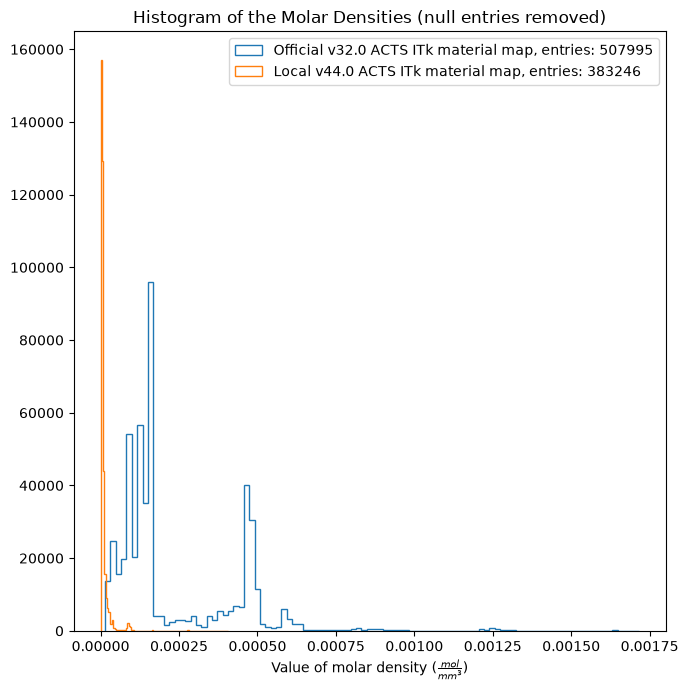

In [9]:
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111)
ax.hist(acts_molar, bins = 100, histtype = 'step', label = f"Official v32.0 ACTS ITk material map, entries: {n_acts_entries}")
ax.hist(local_molar, bins = 100, histtype = 'step', label = f"Local v44.0 ACTS ITk material map, entries: {n_local_entries}")
plt.xlabel(r"Value of molar density $(\frac{mol}{mm^3})$")
plt.legend()
plt.title('Histogram of the Molar Densities (null entries removed)')
plt.tight_layout()

## Study of the Empty Bins:
Compare the average number of empty bins per surface in the locally produced material map versus the official material map.

In [10]:
def empty_fraction_by_entry(rows):
    groups = defaultdict(list)
    for rec in rows:
        eid = rec.get("entry_idx")
        dens = rec.get('Molar Density')

        if isinstance(dens, (list, tuple)):
            groups[eid].extend(dens)
        else:
            groups[eid].append(dens)
    out = []
    for eid in sorted(groups.keys()):
        empty = non = 0
        for v in groups[eid]:
            if v is None or v == "None":
                empty += 1
                continue
            try:
                x = float(v)
            except (TypeError, ValueError):
                empty += 1
                continue
            if math.isnan(x) or x == 0.0:
                empty += 1
            else:
                non += 1
        total = empty + non
        out.append({
            "entry_idx": eid,
            "empty_frac": (empty / total) if total else 1.0
        })
    return out

In [11]:
empty_fraction_local_array = empty_fraction_by_entry(local_entry_data)
fraction_local = [entry["empty_frac"] for entry in empty_fraction_local_array]
empty_fraction_acts_array = empty_fraction_by_entry(acts_entry_data)
fraction_acts = [entry["empty_frac"] for entry in empty_fraction_acts_array]

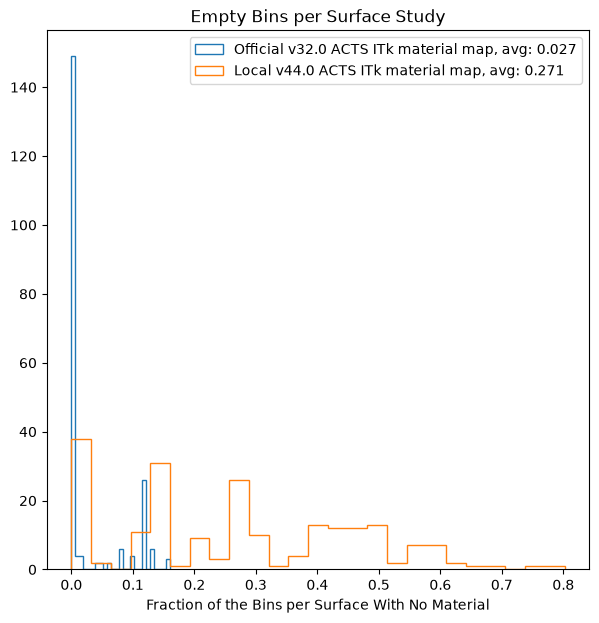

In [12]:
avg_fraction_acts = np.mean(fraction_acts)
avg_fraction_local = np.mean(fraction_local)
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)
ax.hist(fraction_acts, bins = 25, histtype = 'step', label = f"Official v32.0 ACTS ITk material map, avg: {avg_fraction_acts:.3f}")
ax.hist(fraction_local, bins = 25, histtype = 'step', label = f"Local v44.0 ACTS ITk material map, avg: {avg_fraction_local:.3f}")
plt.xlabel('Fraction of the Bins per Surface With No Material')
plt.title('Empty Bins per Surface Study')
plt.legend()
plt.show()

## Comparison of Material Map 'Thickness' Value from Local map verus Official Map:
Compare the average thickness value for every surface in both maps

In [13]:
local_thickness = defaultdict(list)
total_local_thickness = []
for e in local_entry_data:
    id_tuple = e['id_tuple']
    thickness = e['thickness']
    local_thickness[id_tuple].append(thickness)
    total_local_thickness.append(thickness)
local_avg_thick = []
for i in sorted(local_thickness.keys()):
    local_avg_thickness = np.mean(local_thickness[i])
    local_avg_thick.append(local_avg_thickness)
    print(f"surface={i}: avg_thickness: {local_avg_thickness}")

surface=(2, 1): avg_thickness: 5759.046538330078
surface=(2, 2, 2): avg_thickness: 10.264119133377076
surface=(2, 3): avg_thickness: 62.07985550537109
surface=(2, 4, 2): avg_thickness: 200.9862448501587
surface=(6, 2): avg_thickness: 7.405714089529855
surface=(8, 2, 2): avg_thickness: 152.27532559337615
surface=(8, 4, 2): avg_thickness: 160.89176797122954
surface=(8, 6, 2): avg_thickness: 176.30800190820693
surface=(8, 8, 2): avg_thickness: 185.0362704925537
surface=(8, 10, 2): avg_thickness: 115.93355335235596
surface=(8, 12, 2): avg_thickness: 144.4995824028015
surface=(8, 14, 2): avg_thickness: 131.06214137115478
surface=(8, 16, 2): avg_thickness: 129.7265705848694
surface=(8, 18, 2): avg_thickness: 155.5057363922119
surface=(8, 20, 2): avg_thickness: 116.49280016059876
surface=(8, 22, 2): avg_thickness: 106.8778265182495
surface=(8, 24, 2): avg_thickness: 102.64057026023865
surface=(8, 26, 2): avg_thickness: 95.9651743850708
surface=(8, 28, 2): avg_thickness: 102.93209639663696
sur

In [14]:
acts_thickness = defaultdict(list)
total_acts_thickness = []
for e in acts_entry_data:
    id_tuple = e['id_tuple']
    thickness = e['thickness']
    acts_thickness[id_tuple].append(thickness)
    total_acts_thickness.append(thickness)
acts_avg_thick = []
for i in sorted(acts_thickness.keys()):
    acts_avg_thickness = np.mean(acts_thickness[i])
    acts_avg_thick.append(acts_avg_thickness)
    print(f"surface={i}: avg_thickness = {acts_avg_thickness}")

surface=(2, 1): avg_thickness = 277.7018663368225
surface=(2, 2, 2): avg_thickness = 10.390655446052552
surface=(2, 3): avg_thickness = 45.29266437225342
surface=(2, 4, 2): avg_thickness = 95.39426012039185
surface=(6, 2): avg_thickness = 3.8993172577449253
surface=(8, 2, 2): avg_thickness = 5.254696095987735
surface=(8, 4, 2): avg_thickness = 9.768424779709335
surface=(8, 6, 2): avg_thickness = 5.045461948687211
surface=(8, 8, 2): avg_thickness = 6.118609144055099
surface=(8, 10, 2): avg_thickness = 4.845920463323593
surface=(8, 12, 2): avg_thickness = 6.048362075291574
surface=(8, 14, 2): avg_thickness = 4.626566571044922
surface=(8, 16, 2): avg_thickness = 5.975572089663148
surface=(8, 18, 2): avg_thickness = 4.620316028308868
surface=(8, 20, 2): avg_thickness = 5.919564232039452
surface=(8, 22, 2): avg_thickness = 4.321754505443573
surface=(8, 24, 2): avg_thickness = 5.852579641383886
surface=(8, 26, 2): avg_thickness = 4.319192378234863
surface=(8, 28, 2): avg_thickness = 4.549750

In [15]:
print(f"Local Map, avg thickness for entire map: {np.mean(total_local_thickness)}, max thicknes of entire map: {np.max(total_local_thickness)}")
print(f"ACTS Map, avg thickness for entire map: {np.mean(total_acts_thickness)}, max thickness of entire map: {np.max(total_acts_thickness)}")

Local Map, avg thickness for entire map: 113.96344808231427, max thicknes of entire map: 22561.775390625
ACTS Map, avg thickness for entire map: 8.884186041260508, max thickness of entire map: 2824.316650390625


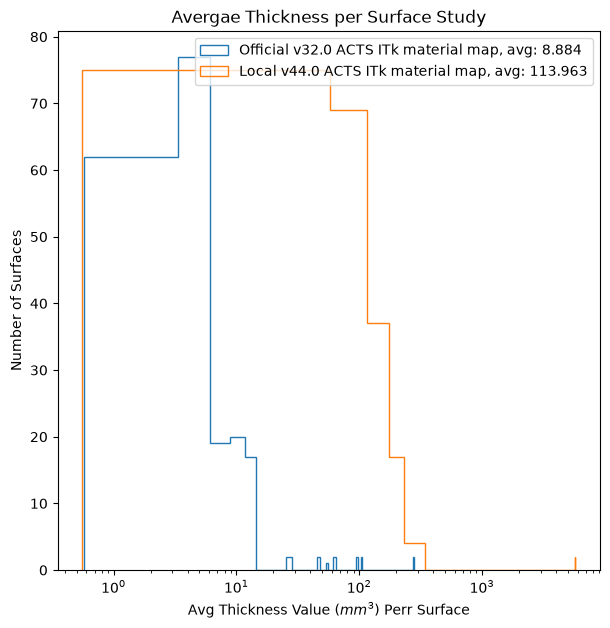

In [16]:
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)
ax.hist(acts_avg_thick, bins = 100, histtype = 'step', label = f"Official v32.0 ACTS ITk material map, avg: {np.mean(total_acts_thickness):.3f}")
ax.hist(local_avg_thick, bins = 100, histtype = 'step', label = f"Local v44.0 ACTS ITk material map, avg: {np.mean(total_local_thickness):.3f}")
plt.xlabel(r'Avg Thickness Value $(mm^3)$ Perr Surface')
ax.set_xscale('log')
plt.ylabel('Number of Surfaces')
plt.title('Avergae Thickness per Surface Study')
plt.legend()
plt.show()

## Results
#### The locally produced ACTS v44.0 material map had:  
- Surfaces that contained bins in which on average 27% of the bins were without material assignment
- The average molar density for the entire local map was: $8.812*10^{-6} \mathrm{(\frac{mol}{mm^3})}$
- The average thickness of the entire local map was $113.96 (\mathrm{mm^3})$
    - The two surfaces with the larges thickness values, (2, 2) and (25, 2) had avg. thickness $ =\approx 5760 (\mathrm{mm^3})$ with a total maximum of thickness $= 22561.77 (\mathrm{mm^3})$

#### The Official ACTS v32.0 material map had:
- Surfaces that contained bins in which on average 2.7% of the bins were without material assignment
- The average molar density for the entire local map was: $2.315*10^{-4} \mathrm{(\frac{mol}{mm^3})}$
- The average thickness of the entire local map was $8.884 (\mathrm{mm^3})$
    - The two surfaces with the larges thickness values, (2, 2) and (25, 2) had avg. thickness $=\approx 277 (\mathrm{mm^3})$ with a total maximum of thickness $= 2824.32 (\mathrm{mm^3})$
 
<br>
The entire length of the ITk is $\approx 6 \mathrm{m}$, if a single surface in the inputted material map has a 'thickness' value of $\approx 22 \mathrm{m}$, that is not a valid input and the mateiral mapping procedure needs to be improved